# Etapa 1 do pipeline de cosegmentação — laboratório visual

Este notebook reproduz, em escala pequena, a lógica de
`pipeline/step1_feature_extraction.py`.

Ele acompanha os nove passos do resumo mental:

1. localizar e abrir as imagens;
2. redimensionar preservando a razão de aspecto;
3. dividir visualmente a entrada em patches de 14×14;
4. carregar o DINOv2;
5. extrair o token CLS e os patch tokens;
6. visualizar as features locais usando PCA;
7. comparar as imagens usando os tokens CLS;
8. procurar patches correspondentes entre imagens;
9. normalizar por L2 e salvar `features.npz`.

Use inicialmente apenas **2 a 4 imagens** da mesma categoria. A primeira
execução baixa os pesos do DINOv2. O modelo ViT-S/14 funciona em CPU, mas
será consideravelmente mais rápido em uma GPU CUDA.

> **⚠️ Atenção aos defaults — CLI do script vs. config do pipeline.**
> Os defaults do `argparse` em `step1_feature_extraction.py` são
> `--resize square` e `--feature_mode raw`. Este notebook **não** usa esses
> defaults do CLI — ele reproduz a configuração que `run_pipeline.sh`
> efetivamente usa em produção (`DINO_RESIZE="keep_ar"`,
> `DINO_FEATURE_MODE="l2"`, `dinov2_vits14`, `img_size=518`), que é a
> combinação validada por ablação como a que melhor generaliza (ver
> comentários em `run_pipeline.sh`, linhas ~129-136 e ~154). Se você rodar o
> script `.py` isoladamente sem passar `--resize keep_ar --feature_mode l2`
> explicitamente, vai obter um resultado *diferente* do que a pipeline real
> produz — vale sempre conferir com que flags a Etapa 1 foi de fato invocada.


In [10]:
# Se necessário, descomente e execute:
# %pip install torch torchvision pillow matplotlib numpy scikit-learn



In [11]:
from pathlib import Path
import math

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
import torch
from PIL import Image
from sklearn.decomposition import PCA
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.preprocessing import normalize as l2_normalize

plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["image.cmap"] = "viridis"

IMAGE_DIR = Path("imagens_etapa1")  # <-- altere para sua pasta
IMG_SIZE = 518
PATCH_SIZE = 14
MODEL_NAME = "dinov2_vits14"
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)
VALID_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}

# Estes valores replicam DINOV2_MODEL / DINO_IMG_SIZE / DINO_RESIZE /
# DINO_FEATURE_MODE de run_pipeline.sh — a config calibrada, não os
# defaults "crus" do argparse de step1_feature_extraction.py.
RESIZE_MODE = "keep_ar"
FEATURE_MODE = "l2"

print("Dispositivo:", "cuda" if torch.cuda.is_available() else "cpu")
print("Pasta de imagens:", IMAGE_DIR.resolve())


Dispositivo: cuda
Pasta de imagens: /mnt/e/github/cosegmentation/study/imagens_etapa1


## Passo 1 — abrir e inspecionar as imagens

As imagens podem ter dimensões e razões de aspecto diferentes. O pipeline
precisa transformá-las em entradas com a mesma grade de patches para poder
empilhar as features em um tensor `(N, P, D)`.



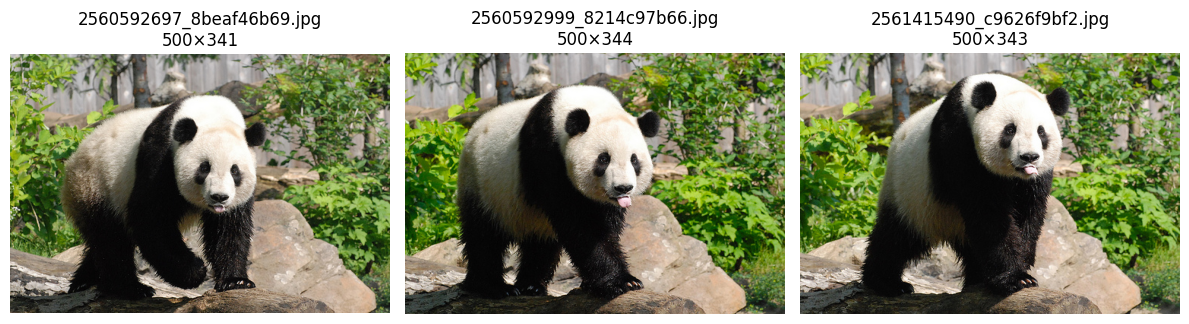

In [12]:
image_paths = sorted(p for p in IMAGE_DIR.iterdir() if p.suffix.lower() in VALID_EXTENSIONS)
assert len(image_paths) >= 2, "Coloque pelo menos duas imagens em IMAGE_DIR."

fig, axes = plt.subplots(1, len(image_paths), figsize=(4 * len(image_paths), 4), squeeze=False)
for ax, path in zip(axes[0], image_paths):
    image = Image.open(path).convert("RGB")
    ax.imshow(image)
    ax.set_title(f"{path.name}\n{image.width}×{image.height}")
    ax.axis("off")
plt.tight_layout()



## Passo 2 — `keep_ar`: redimensionamento e padding

O maior lado é redimensionado para 518 pixels. O outro lado é completado com
padding até formar um canvas 518×518. A cor do padding é a média da ImageNet;
após a normalização dos pixels, ela fica aproximadamente próxima de zero.



Formato do tensor entregue ao modelo: (1, 3, 518, 518)
resize_info = (353, 518, 82, 0, 518, 518)


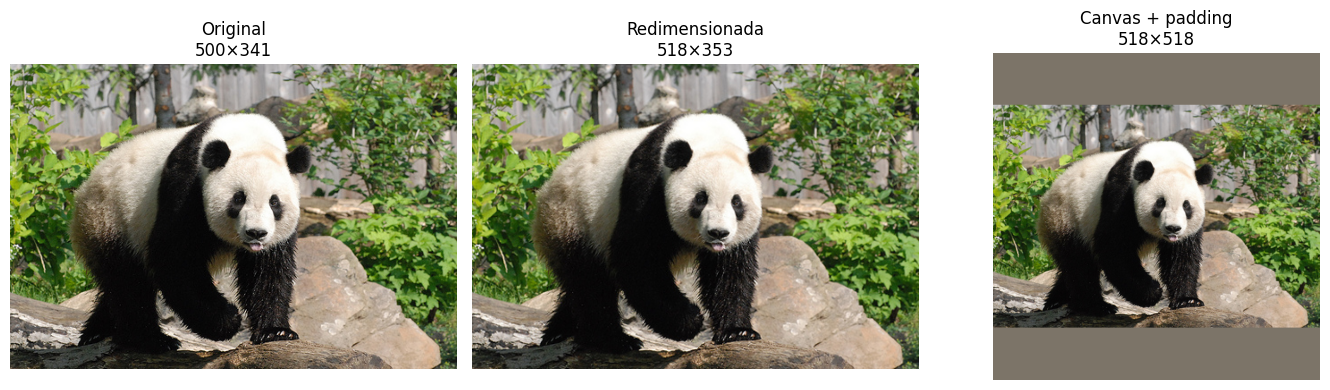

In [13]:
def preprocess_visual(path: Path, img_size: int = IMG_SIZE):
    original = Image.open(path).convert("RGB")
    target = max(PATCH_SIZE, (img_size // PATCH_SIZE) * PATCH_SIZE)
    scale = target / max(original.width, original.height)
    new_w = max(1, min(target, int(round(original.width * scale))))
    new_h = max(1, min(target, int(round(original.height * scale))))
    resized = original.resize((new_w, new_h), Image.Resampling.BICUBIC)

    pad_color = tuple(int(round(v * 255)) for v in IMAGENET_MEAN)
    canvas = Image.new("RGB", (target, target), pad_color)
    pad_left = (target - new_w) // 2
    pad_top = (target - new_h) // 2
    canvas.paste(resized, (pad_left, pad_top))

    arr = np.asarray(canvas, dtype=np.float32) / 255.0
    normalized = (arr - np.asarray(IMAGENET_MEAN)) / np.asarray(IMAGENET_STD)
    tensor = torch.from_numpy(normalized).permute(2, 0, 1).unsqueeze(0).float()
    info = (new_h, new_w, pad_top, pad_left, target, target)
    return original, resized, canvas, tensor, info


example = image_paths[0]
original, resized, canvas, tensor, resize_info = preprocess_visual(example)
new_h, new_w, pad_top, pad_left, canvas_h, canvas_w = resize_info

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].imshow(original); axes[0].set_title(f"Original\n{original.width}×{original.height}")
axes[1].imshow(resized); axes[1].set_title(f"Redimensionada\n{new_w}×{new_h}")
axes[2].imshow(canvas); axes[2].set_title(f"Canvas + padding\n{canvas_w}×{canvas_h}")
for ax in axes: ax.axis("off")
plt.tight_layout()

print("Formato do tensor entregue ao modelo:", tuple(tensor.shape))
print("resize_info =", resize_info)



O formato `(1, 3, 518, 518)` significa:

- 1 imagem no batch;
- 3 canais RGB;
- altura 518;
- largura 518.



### Extra — por que não usar `resize='square'`?

O CLI de `step1_feature_extraction.py` tem `square` como default: ele
redimensiona direto para `img_size × img_size`, **distorcendo** a proporção
da imagem. É mais simples (nenhum patch é "desperdiçado" com padding), mas
deforma objetos alongados ou muito largos/altos — algo arriscado para um
backbone que description regiões por aparência local.

`keep_ar` evita a distorção, ao custo de parte da grade virar padding. A
célula abaixo compara os dois lado a lado para a mesma imagem.


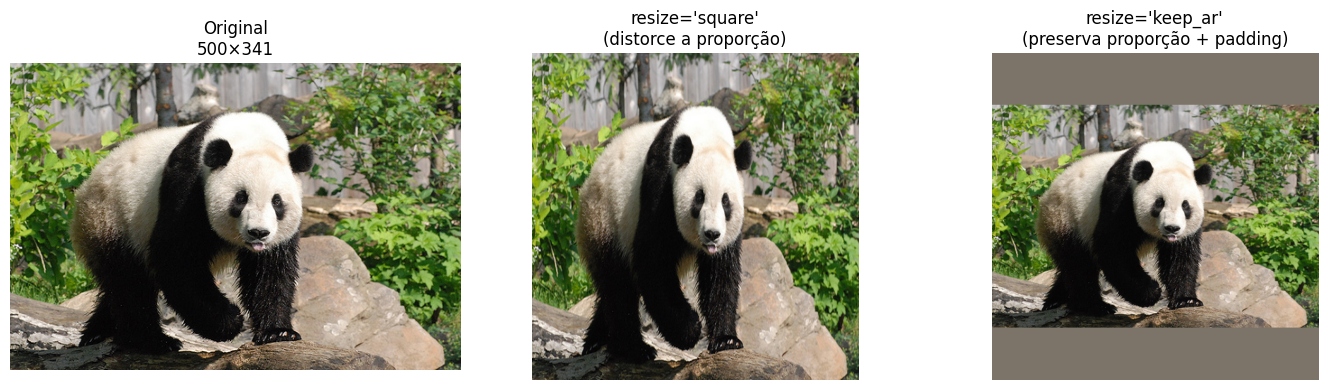

In [14]:
def preprocess_square(path: Path, img_size: int = IMG_SIZE):
    original = Image.open(path).convert("RGB")
    target = max(PATCH_SIZE, (img_size // PATCH_SIZE) * PATCH_SIZE)
    return original.resize((target, target), Image.Resampling.BICUBIC)


square_version = preprocess_square(example)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].imshow(original)
axes[0].set_title(f"Original\n{original.width}×{original.height}")
axes[1].imshow(square_version)
axes[1].set_title("resize='square'\n(distorce a proporção)")
axes[2].imshow(canvas)
axes[2].set_title("resize='keep_ar'\n(preserva proporção + padding)")
for ax in axes:
    ax.axis("off")
plt.tight_layout()


Repare como `square` pode esticar ou espremer o objeto (mais visível quanto
mais a imagem original fugir de 1:1), enquanto `keep_ar` mantém as
proporções corretas e só adiciona uma faixa de padding neutro (cor média da
ImageNet) nas bordas. É esse padding que o próximo bloco quantifica.


## Passo 3 — enxergar a grade de patches

O ViT-S/14 divide implicitamente a entrada em blocos de 14×14 pixels.
Como `518 / 14 = 37`, são 37×37 = 1369 patches.



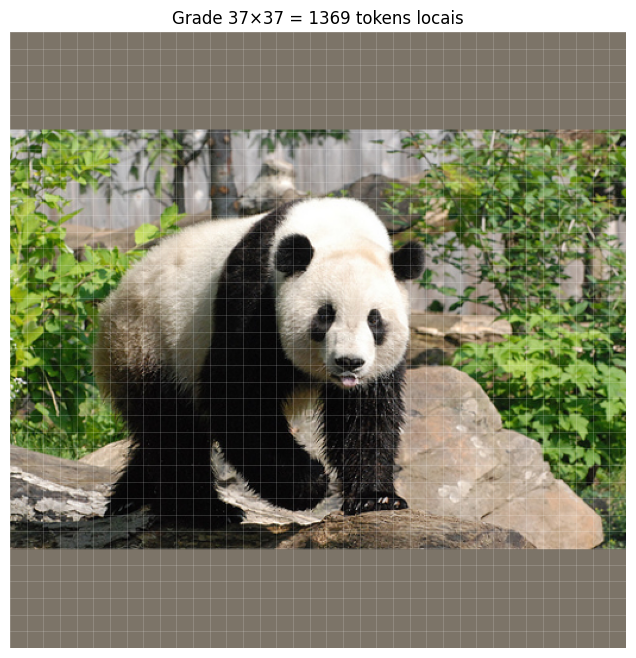

In [15]:
grid_h = canvas_h // PATCH_SIZE
grid_w = canvas_w // PATCH_SIZE

fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(canvas)
for x in range(0, canvas_w + 1, PATCH_SIZE):
    ax.axvline(x - 0.5, color="white", alpha=0.22, linewidth=0.5)
for y in range(0, canvas_h + 1, PATCH_SIZE):
    ax.axhline(y - 0.5, color="white", alpha=0.22, linewidth=0.5)
ax.set_title(f"Grade {grid_h}×{grid_w} = {grid_h * grid_w} tokens locais")
ax.axis("off")
plt.show()



Cada quadrado terá um vetor com 384 valores. Ele não corresponde a uma classe
pronta como “panda”. É uma descrição aprendida e contextualizada daquela
região.



## Passo 4 — carregar o DINOv2

`dinov2_vits14` é um Vision Transformer pequeno, com patches 14×14. O modelo
já vem treinado; neste laboratório não haverá treinamento nem ajuste de pesos.



In [16]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = torch.hub.load("facebookresearch/dinov2", MODEL_NAME, pretrained=True)
model = model.eval().to(device)

print("Modelo:", MODEL_NAME)
print("Parâmetros:", f"{sum(p.numel() for p in model.parameters()) / 1e6:.1f} milhões")
print("Dispositivo:", device)



Using cache found in /home/lucas/.cache/torch/hub/facebookresearch_dinov2_main


Modelo: dinov2_vits14
Parâmetros: 22.1 milhões
Dispositivo: cuda


## Passo 5 — extrair CLS e patch tokens

A saída local terá forma `(N, 1369, 384)`. A saída CLS terá forma
`(N, 384)`. O CLS resume globalmente a imagem; cada patch token representa
uma posição da grade já contextualizada pelos outros patches.



In [17]:
@torch.no_grad()
def extract_all(paths):
    patch_features = []
    cls_features = []
    canvases = []
    image_sizes = []
    resize_infos = []

    for path in paths:
        original, _, canvas, tensor, info = preprocess_visual(path)
        output = model.get_intermediate_layers(
            tensor.to(device), n=1, return_class_token=True
        )
        patch_tokens, cls_token = output[0]
        patch_features.append(patch_tokens.squeeze(0).cpu().numpy())
        cls_features.append(cls_token.squeeze(0).cpu().numpy())
        canvases.append(canvas)
        image_sizes.append((original.height, original.width))
        resize_infos.append(info)
        print(f"{path.name:35s} patches={tuple(patch_tokens.shape)} CLS={tuple(cls_token.shape)}")

    return (
        np.stack(patch_features),
        np.stack(cls_features),
        canvases,
        np.asarray(image_sizes),
        np.asarray(resize_infos),
    )


patch_raw, cls_raw, canvases, image_sizes, resize_infos = extract_all(image_paths)
print("\npatch_raw:", patch_raw.shape)
print("cls_raw:  ", cls_raw.shape)



2560592697_8beaf46b69.jpg           patches=(1, 1369, 384) CLS=(1, 384)
2560592999_8214c97b66.jpg           patches=(1, 1369, 384) CLS=(1, 384)
2561415490_c9626f9bf2.jpg           patches=(1, 1369, 384) CLS=(1, 384)

patch_raw: (3, 1369, 384)
cls_raw:   (3, 384)


### Extra — máscara de conteúdo: quantos patches são padding?

Cada `resize_info` guarda `(new_h, new_w, pad_top, pad_left, canvas_h, canvas_w)`.
Com isso dá para saber, patch a patch, quais caem dentro da imagem
redimensionada e quais caem na faixa de padding — a mesma lógica de
`compute_content_mask()` usada nos analisadores das Etapas 2 e 3 para excluir
patches de padding das métricas (não supervisionadas, baseadas em GT e de
acurácia de orientação). O critério aqui é simples — o **centro** do patch
precisa cair dentro da região redimensionada — só para fins didáticos; a
implementação real pode usar um critério de sobreposição diferente.


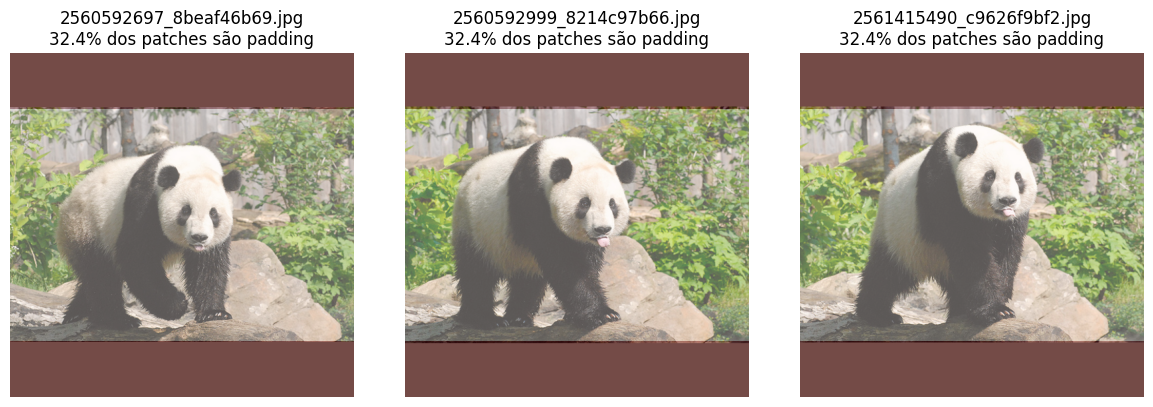

In [18]:
def compute_content_mask(resize_info, grid_h, grid_w, patch_size=PATCH_SIZE):
    new_h, new_w, pad_top, pad_left, canvas_h, canvas_w = resize_info
    mask = np.zeros((grid_h, grid_w), dtype=bool)
    for r in range(grid_h):
        y0, y1 = r * patch_size, (r + 1) * patch_size
        cy = (y0 + y1) / 2
        for c in range(grid_w):
            x0, x1 = c * patch_size, (c + 1) * patch_size
            cx = (x0 + x1) / 2
            if pad_top <= cy < pad_top + new_h and pad_left <= cx < pad_left + new_w:
                mask[r, c] = True
    return mask


N = len(image_paths)  # ainda nao foi definido nesta altura do notebook (so no Passo 6)
content_masks = np.stack([
    compute_content_mask(resize_infos[i], grid_h, grid_w) for i in range(N)
])

fig, axes = plt.subplots(1, N, figsize=(4 * N, 4), squeeze=False)
for i, path in enumerate(image_paths):
    axes[0, i].imshow(canvases[i])
    axes[0, i].imshow(
        ~content_masks[i], extent=(0, IMG_SIZE, IMG_SIZE, 0),
        cmap="Reds", alpha=0.35, vmin=0, vmax=1, interpolation="nearest",
    )
    frac_pad = 1 - content_masks[i].mean()
    axes[0, i].set_title(f"{path.name}\n{frac_pad:.1%} dos patches são padding")
    axes[0, i].axis("off")
plt.tight_layout()


Quanto mais a imagem original fugir de uma proporção 1:1, maior a área em
vermelho — mais patches "desperdiçados" em padding, e mais patches que
**precisam** ser excluídos de qualquer métrica calculada sobre a grade,
sob risco de viés sistemático (menos ainda em direções específicas — o
padding tende a se concentrar nas bordas superior/inferior ou
esquerda/direita, nunca no centro).


## Passo 6 — tornar 384 dimensões visíveis com PCA

Não conseguimos mostrar diretamente um vetor de 384 dimensões como uma cor.
O PCA projeta todos os patch tokens conjuntamente em três dimensões, que são
convertidas em RGB. Cores parecidas indicam representações parecidas.

Isso é apenas uma visualização: o pipeline continua usando as 384 dimensões.



Variância explicada pelas 3 componentes: [0.24181716 0.14217721 0.08376703]


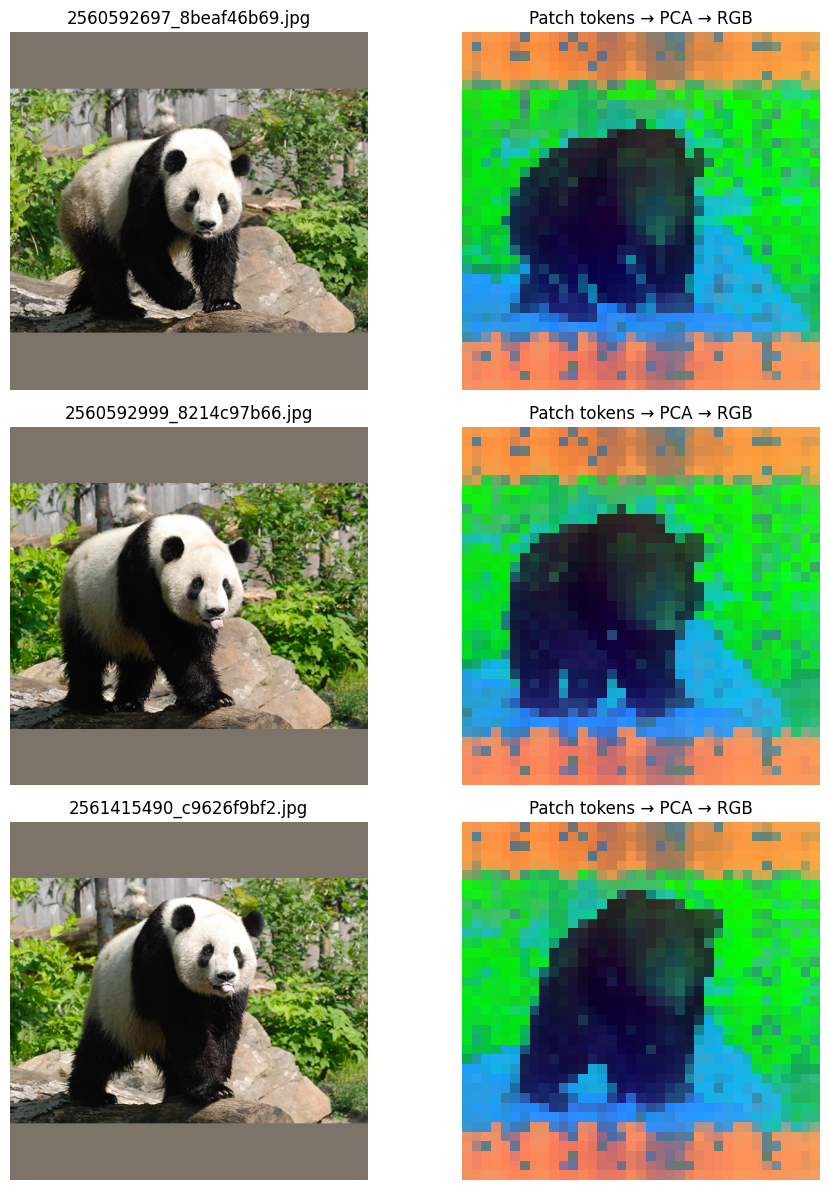

In [19]:
N, P, D = patch_raw.shape
pca = PCA(n_components=3, random_state=42)
pca_3d = pca.fit_transform(patch_raw.reshape(-1, D))
lo, hi = np.percentile(pca_3d, 1, axis=0), np.percentile(pca_3d, 99, axis=0)
pca_rgb = np.clip((pca_3d - lo) / (hi - lo + 1e-8), 0, 1).reshape(N, grid_h, grid_w, 3)

fig, axes = plt.subplots(N, 2, figsize=(10, 4 * N), squeeze=False)
for i, path in enumerate(image_paths):
    axes[i, 0].imshow(canvases[i]); axes[i, 0].set_title(path.name)
    axes[i, 1].imshow(pca_rgb[i], interpolation="nearest")
    axes[i, 1].set_title("Patch tokens → PCA → RGB")
    for ax in axes[i]: ax.axis("off")
plt.tight_layout()

print("Variância explicada pelas 3 componentes:", pca.explained_variance_ratio_)



Procure regiões do objeto comum que recebem cores semelhantes nas imagens.
A correspondência não será perfeita: PCA descarta 381 dimensões e serve só
para formar uma intuição visual.



## Passo 7 — similaridade global pelos tokens CLS

Depois da normalização L2, o produto interno equivale à similaridade por
cosseno. A matriz abaixo mostra quais imagens são globalmente mais próximas.

> Note que a normalização L2 já é aplicada aqui, antes de ela ser explicada
> em detalhe no Passo 9 — ela é o que torna o produto interno equivalente ao
> cosseno. Sem normalizar, dois vetores na mesma direção mas com magnitudes
> diferentes pareceriam "menos parecidos" do que realmente são.


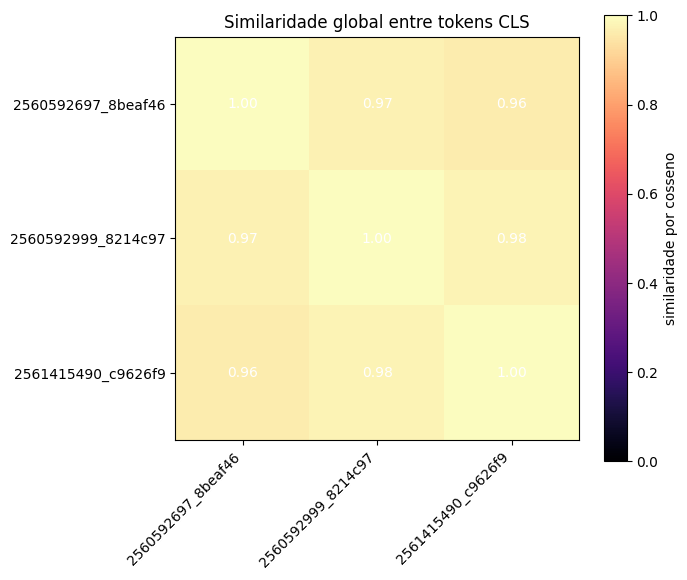

In [20]:
cls_l2 = l2_normalize(cls_raw, axis=1)
cls_sim = cls_l2 @ cls_l2.T

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cls_sim, vmin=0, vmax=1, cmap="magma")
short_names = [p.stem[:18] for p in image_paths]
ax.set_xticks(range(N), short_names, rotation=45, ha="right")
ax.set_yticks(range(N), short_names)
for i in range(N):
    for j in range(N):
        ax.text(j, i, f"{cls_sim[i, j]:.2f}", ha="center", va="center", color="white")
ax.set_title("Similaridade global entre tokens CLS")
fig.colorbar(im, ax=ax, label="similaridade por cosseno")
plt.tight_layout()



A diagonal sempre vale 1 porque cada imagem é comparada consigo mesma. Na E2,
essa informação global ajuda a escolher pares de imagens promissores.



## Passo 8 — procurar correspondências locais

Escolha manualmente uma coordenada da grade. O notebook usará o vetor desse
patch como consulta e calculará sua similaridade com todos os patches de todas
as imagens.

Experimente mudar `QUERY_ROW` e `QUERY_COL`. Uma estratégia simples é olhar a
grade do Passo 3 e escolher um quadrado localizado sobre o objeto comum.

> De novo, `patch_l2` normaliza os vetores por L2 antes do produto interno,
> pelo mesmo motivo do Passo 7: comparar direção, não magnitude.


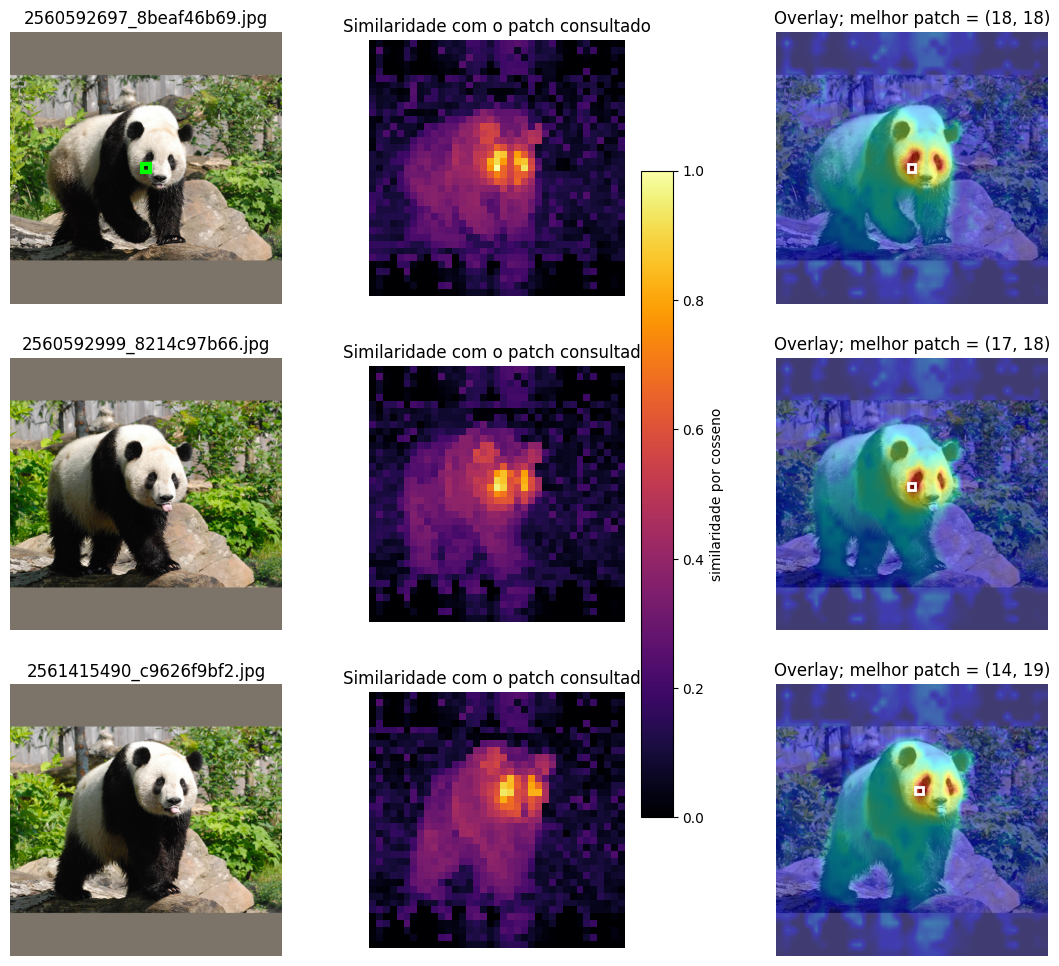

In [21]:
QUERY_IMAGE = 0
QUERY_ROW = grid_h // 2
QUERY_COL = grid_w // 2

assert 0 <= QUERY_IMAGE < N
assert 0 <= QUERY_ROW < grid_h and 0 <= QUERY_COL < grid_w

patch_l2 = l2_normalize(patch_raw.reshape(-1, D), axis=1).reshape(N, P, D)
query_index = QUERY_ROW * grid_w + QUERY_COL
query = patch_l2[QUERY_IMAGE, query_index]
similarity_maps = (patch_l2 @ query).reshape(N, grid_h, grid_w)

fig, axes = plt.subplots(N, 3, figsize=(14, 4 * N), squeeze=False)
for i, path in enumerate(image_paths):
    axes[i, 0].imshow(canvases[i])
    axes[i, 0].set_title(path.name)
    if i == QUERY_IMAGE:
        rect = mpatches.Rectangle(
            (QUERY_COL * PATCH_SIZE, QUERY_ROW * PATCH_SIZE),
            PATCH_SIZE, PATCH_SIZE, fill=False, edgecolor="lime", linewidth=3
        )
        axes[i, 0].add_patch(rect)

    heat = axes[i, 1].imshow(similarity_maps[i], vmin=0, vmax=1, cmap="inferno", interpolation="nearest")
    axes[i, 1].set_title("Similaridade com o patch consultado")

    axes[i, 2].imshow(canvases[i])
    axes[i, 2].imshow(
        similarity_maps[i], extent=(0, IMG_SIZE, IMG_SIZE, 0),
        vmin=0, vmax=1, cmap="jet", alpha=0.48, interpolation="bilinear"
    )
    best = int(np.argmax(similarity_maps[i]))
    br, bc = divmod(best, grid_w)
    axes[i, 2].add_patch(mpatches.Rectangle(
        (bc * PATCH_SIZE, br * PATCH_SIZE), PATCH_SIZE, PATCH_SIZE,
        fill=False, edgecolor="white", linewidth=2
    ))
    axes[i, 2].set_title(f"Overlay; melhor patch = ({br}, {bc})")
    for ax in axes[i]: ax.axis("off")

fig.colorbar(heat, ax=axes[:, 1], shrink=0.7, label="similaridade por cosseno")
plt.show()



Esta é a experiência que mais se aproxima da ideia da E2: uma região de uma
imagem “vota” em regiões semanticamente semelhantes das outras imagens.

Observe também possíveis erros:

- fundo recorrente recebendo similaridade alta;
- patches misturando objeto e fundo;
- padding aparecendo como correspondência;
- partes distintas do mesmo objeto produzindo features diferentes.



## Passo 9 — efeito da normalização L2

A normalização força cada vetor a ter norma 1. Ela remove a magnitude e faz a
comparação depender da direção do vetor.



patch_raw: (3, 1369, 384)
patch_l2:  (3, 1369, 384)
raw_norms: (3, 1369)
l2_norms:  (3, 1369)

Antes da normalização:
mínimo=42.009438  média=50.208447  máximo=56.092232

Depois da normalização:
mínimo=0.999999762  média=1.000000000  máximo=1.000000119


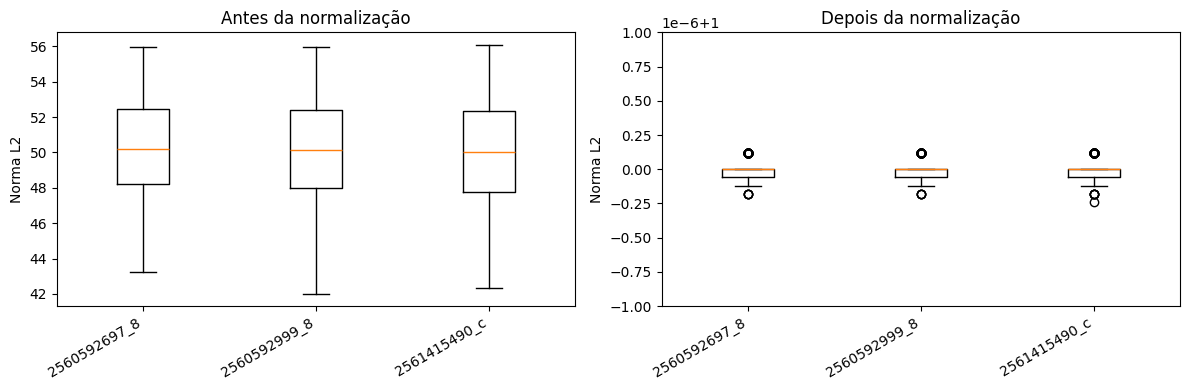

In [22]:
# Norma de cada patch antes e depois da normalização L2.
# Formato dos dois arrays: (N, P)
raw_norms = np.linalg.norm(patch_raw, axis=-1)
l2_norms = np.linalg.norm(patch_l2, axis=-1)

print("patch_raw:", patch_raw.shape)
print("patch_l2: ", patch_l2.shape)
print("raw_norms:", raw_norms.shape)
print("l2_norms: ", l2_norms.shape)

print("\nAntes da normalização:")
print(
    f"mínimo={raw_norms.min():.6f}  "
    f"média={raw_norms.mean():.6f}  "
    f"máximo={raw_norms.max():.6f}"
)

print("\nDepois da normalização:")
print(
    f"mínimo={l2_norms.min():.9f}  "
    f"média={l2_norms.mean():.9f}  "
    f"máximo={l2_norms.max():.9f}"
)

labels = [p.stem[:12] for p in image_paths]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].boxplot(
    [raw_norms[i].ravel() for i in range(len(image_paths))]
)
axes[0].set_xticks(
    range(1, len(labels) + 1),
    labels,
    rotation=30,
    ha="right"
)
axes[0].set_title("Antes da normalização")
axes[0].set_ylabel("Norma L2")

axes[1].boxplot(
    [l2_norms[i].ravel() for i in range(len(image_paths))]
)
axes[1].set_xticks(
    range(1, len(labels) + 1),
    labels,
    rotation=30,
    ha="right"
)
axes[1].set_title("Depois da normalização")
axes[1].set_ylabel("Norma L2")
axes[1].set_ylim(0.999999, 1.000001)

plt.tight_layout()
plt.show()

## Salvar o mesmo tipo de artefato da Etapa 1

O arquivo abaixo contém as representações que as etapas seguintes consomem.
Ele é didático e compatível em estrutura com os principais campos da E1.



In [23]:
output_path = Path("features_notebook.npz")
np.savez_compressed(
    output_path,
    patch_features=patch_l2.astype(np.float32),
    cls_features=cls_l2.astype(np.float32),
    patch_grid=np.asarray((grid_h, grid_w)),
    image_paths=np.asarray([str(p) for p in image_paths]),
    image_sizes=image_sizes,
    resize_mode=np.asarray("keep_ar"),
    resize_info=resize_infos.astype(np.int32),
    feature_mode=np.asarray("l2"),
)

loaded = np.load(output_path, allow_pickle=True)
print("Salvo em:", output_path.resolve())
print("\nConteúdo:")
for key in loaded.files:
    value = loaded[key]
    print(f"  {key:18s} shape={value.shape!s:16s} dtype={value.dtype}")



Salvo em: /mnt/e/github/cosegmentation/study/features_notebook.npz

Conteúdo:
  patch_features     shape=(3, 1369, 384)   dtype=float32
  cls_features       shape=(3, 384)         dtype=float32
  patch_grid         shape=(2,)             dtype=int64
  image_paths        shape=(3,)             dtype=<U40
  image_sizes        shape=(3, 2)           dtype=int64
  resize_mode        shape=()               dtype=<U7
  resize_info        shape=(3, 6)           dtype=int32
  feature_mode       shape=()               dtype=<U2


## Mapa mental final

```text
imagem original
     ↓
resize proporcional + padding
     ↓
tensor RGB normalizado: (1, 3, 518, 518)
     ↓
grade implícita: 37 × 37 patches
     ↓
DINOv2 ViT-S/14
     ├── CLS: 384 valores por imagem
     └── patches: 1369 × 384 valores por imagem
              ↓
        normalização L2
              ↓
         features.npz
```

O DINOv2 ainda não decidiu o que é foreground. Ele apenas construiu um espaço
no qual regiões semelhantes podem ser comparadas. Correspondência, decisão de
foreground e máscaras aparecem nas etapas posteriores.

**Dois pontos que vale reter para o resto do pipeline:**

- **`resize_info` não é um subproduto descartável.** É exatamente o que as
  Etapas 2 e 3 usam para reconstruir uma máscara de conteúdo e ignorar
  patches de padding ao calcular métricas — sem isso, métricas não
  supervisionadas, métricas baseadas em GT e comparações de acurácia de
  orientação ficam contaminadas por patches que não pertencem à imagem real.
- **`square` + `raw` são os defaults do `argparse`, mas não são o que a
  pipeline roda.** `run_pipeline.sh` fixa `keep_ar` + `l2` porque essa foi a
  combinação validada por ablação. Ao comparar com outros trabalhos ou ao
  rodar o script isoladamente, confirme sempre com que `--resize` e
  `--feature_mode` a Etapa 1 foi executada — o resultado muda de forma
  significativa entre `square`/`keep_ar` e `raw`/`l2`.
